# 11 · Real screens

Every number so far came from drawn scenes (`helpers/scenes.py`): a still image moved by whole
pixels, most of it as one rigid window - 44 of the 51 validation pages and 19 of the 25 photos
scroll or pan the whole window, with no toolbar, scrollbar or sticky header standing still - and
timed at 30 fps and read at 60, so every change of speed, every stop and every menu lands on a
received frame. That is close to the tile search's own model of the world, and its headline gain
may be the data's as much as its own.

This notebook scores the methods on **real screen recordings**: the YouTube-8M sequences of the
computer categories (`datasets/yt8m-mix.txt`) - Windows desktops, websites, screencasts, Cinema 4D
and Photoshop, editors, maps, phone screens - kept only where a frame shows a screen capture, by
eye: the categories also hold filmed monitors, people talking, and kitchen blenders.

- **Screens, 24-30 fps**: 81 videos, 5 clips of 32 frames each. None was in the run set (it took
  50 fps and up), so nothing here has been trained or tuned on them. Received every second frame,
  the stream is 12-15 fps and the frame to make is the real one between: the same task at half
  the rate - twice the motion between received frames, and the searches' reach (±8 and ±16
  stream pixels) covers half as much of it.
- **Screens, 50-60 fps**: the four of that rate that are screen captures. The 2x task exactly, but
  they were in the run set's training sources, so the trained models (the masked network) have
  seen them.
- **Synthesia**: 10 videos of a piano-roll app - real captures, but falling bars at a constant
  speed, the most rigid motion there is. Kept apart so they do not flatter the rest.

Each clip goes through the stream's own ×2 downscale and H.264 (`degrade.sample`, as the run set,
seeded) and is cut into the client's tiles (`helpers/recorded.py`, `recursive.load`). The scores
are the ones notebooks 9 and 10 use, beside the drawn validation set's for the same methods.

Steps:

1. **The recordings** - a frame of each.
2. **Scores** - every method on every tile, beside the drawn validation set.
3. **What is different** - how much moves, how much changes, and how often one motion per tile fails.
4. **Examples** - typical tiles, picked at the quartiles of the tile search's score.

Needs: the YouTube sequences in `datasets/raw/yt8m-videos`, notebook 10's masked network
(`checkpoints/masked_runs/`) and the drawn validation caches of notebooks 9 and 10. Nothing is
trained or exported; results are cached in `checkpoints/recorded/`.

In [1]:
"""Settings."""

import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import budget, clips, history, masked, models, recorded, runs, show, sources, training
from helpers.recursive import RecursiveSearch
from helpers import recursive
from helpers.training import DEVICE

STILL, SHARPNESS, CAP = 0.1, 10.0, 50.0
CACHE = training.CHECKPOINT_DIR / "recorded"
SEED = 0
training.seed_everything(SEED)

SCREENS = [
    "Cinema_4D/3N2nRlKlbgk", "Cinema_4D/3OnjlqkFClw", "Cinema_4D/6y8iPU4xTZs",
    "Cinema_4D/HuPwUlHWi7M", "Cinema_4D/Wb7GrS8csC8", "Cinema_4D/WqMNDw7zj24",
    "Cinema_4D/YMpf7sjLOsw", "Cinema_4D/YUF6yUFzZR8", "Cinema_4D/ek28bIHBxLE",
    "Cinema_4D/fI49YQ-c7Gg", "Cinema_4D/m077KW7jD_w", "Cinema_4D/zpNnUUQBgMo",
    "Computer/ldH3aBSYGW4", "Digital_painting/CyaXHJjh1E0", "Digital_painting/FpmtImp2jQE",
    "Digital_painting/anv74Y5n2BI", "Digital_painting/kbA1I_1LdLM", "Digital_painting/usj75M0UOIg",
    "Font/NBRptKep6vU", "Font/_pqbCCuxIeM", "Font/uEiWevVqYw0",
    "Map/VFotXCaAxbE", "Map/kOPj4JVxkaE", "Map/rSSVApBDxdk",
    "Map/tb0C1CO4ang", "Map/w1sWRlMQD3U", "Microsoft_Windows/0ElkyEf7bVU",
    "Microsoft_Windows/5XN1agV-pHg", "Microsoft_Windows/5l4GAZxhjkY", "Microsoft_Windows/65KCQsbVjao",
    "Microsoft_Windows/A5HBnSAZEtY", "Microsoft_Windows/EjpH5f9xv90", "Microsoft_Windows/OJzjrFRwouQ",
    "Microsoft_Windows/Tmd9TMyFdEM", "Microsoft_Windows/WqnDsSZJaRk", "Microsoft_Windows/ZyCTAVT_e6M",
    "Microsoft_Windows/gscBIcLm_Gw", "Microsoft_Windows/kVhdOWxQNF8", "Microsoft_Windows/muZ87U-unZE",
    "Microsoft_Windows/rqRovhzewks", "Microsoft_Windows/yAqsK_3gimg", "Microsoft_Windows/yw9xxpdfGbo",
    "Personal_computer/6IkVjaV-PxU", "Personal_computer/wMw8j9qoY24", "Screencast/1_iVs-exIEk",
    "Screencast/1cqdCQZ_rYw", "Screencast/5IWA6qNMiA8", "Screencast/BQldp1LelSY",
    "Screencast/gyogNNYHSuo", "Screencast/i_Vl80pJjdg", "Screencast/jH6J-n6zt4c",
    "Screencast/nAhUUivmD-Q", "Screencast/pykywx452N8", "Screencast/tGRfnsJnSTY",
    "Screenshot/_j1FKT3sdfw", "Sprite_computer_graphics/haAw7_HBc24", "Text_messaging/eYEFLv9do0k",
    "Web_page/AZITFc78-sA", "Web_page/GD9yAOho4zc", "Web_page/QdZj6wYAtZs",
    "Web_page/lrIYoUJqu44", "Web_page/q6CBH_TKEuE", "Website/15qRSwJ6uso",
    "Website/Hh3ms730O1o", "Website/IBA-dN_pSH8", "Website/IdZ8_S0ptJg",
    "Website/VVxYUNZ8u8U", "Website/aP-pZIQs6yE", "Website/md5YK_CxD3s",
    "Website/wCSTWjZ31iA", "Website/xNmwZ1rholY", "Computer/DyS-XDmfjmM",
    "Digital_painting/YUwbMpIbz-w", "Font/JxOaKvheZms", "Microsoft_Windows/1u954QeRdFE",
    "Microsoft_Windows/jKMgt_ugvH0", "Personal_computer/aZeEqvaJzus", "Personal_computer/zqCPKnzmcYA",
    "Sprite_computer_graphics/gmaQQmRPeeM", "Text_messaging/bkoMyKY_cAY", "Web_page/MmNPG0Gn6lc",
]
SYNTHESIA = [
    "Synthesia/2exjc7vLx0c", "Synthesia/3vA2Waiv5uw", "Synthesia/DNtD6V8-PL0",
    "Synthesia/EsAzTy5B_gc", "Synthesia/OLtdrTX15jE", "Synthesia/h_1iiOMovYc",
    "Synthesia/nTcyWr7ahS0", "Synthesia/v8ySoSABhuo", "Synthesia/6_iEpiSccyM",
    "Synthesia/6fz3zq3zfrk",
]
SIXTY = [
    "Digital_painting/vG2G88APxas", "Map/VSn5N7cNiGg", "Microsoft_Windows/XlvlIq-TpDI",
    "Microsoft_Windows/veL8195FELU",
]
GROUPS = {"screens, 24-30 fps": SCREENS, "screens, 50-60 fps (seen in training)": SIXTY, "Synthesia": SYNTHESIA}
SLUG = {"screens, 24-30 fps": "screens30", "screens, 50-60 fps (seen in training)": "screens60", "Synthesia": "synthesia"}
manifest = recorded.manifest(GROUPS, seed=SEED)
for name, split in manifest["splits"].items():
    rates = sorted({round(s["fps"]) for s in split["sources"]})
    print(f"{name:<40} {len({s['video'] for s in split['sources']}):3} videos, {len(split['sources']):4} clips, {rates} fps")

FRACTION = 1 / manifest["received_every"]
published = models.TileSearch(4, 2, SHARPNESS, 2, FRACTION, still=STILL).to(DEVICE).eval()
pyramid = models.PyramidSearch(((4, 4, 1), (2, 1, 2), (1, 2, 4)), SHARPNESS, FRACTION, STILL, "equiangular",
                               whole=True).to(DEVICE).eval()
network = models.Masked(models.TileSearch(4, 2, SHARPNESS, 2, FRACTION, still=STILL), gated=True).to(DEVICE)
state = torch.load(training.CHECKPOINT_DIR / "masked_runs" / "masked_gated.pt", map_location="cpu", weights_only=False)
network.load_state_dict(state["progress"]["best"]["state"])
network.eval()


def as_picture(model):
    model = model.to(DEVICE).eval()
    return lambda previous, current, target: model(previous, current)


PICTURES = {"repeat": lambda previous, current, target: current,
            "mock: linear": as_picture(models.Blend(1.0)),
            "published search": as_picture(models.Motion(search=published, learned=False)),
            "pyramid, whole-pixel (notebook 8)": as_picture(models.Motion(search=pyramid, learned=False)),
            "masked network (notebook 10)": as_picture(network)}
FIELDS = {"3DRS (notebook 9)": RecursiveSearch(16, 3, 16, seeds=("tile", "minima", "blocks"))}

screens, 24-30 fps                        81 videos,  405 clips, [24, 25, 29, 30] fps
screens, 50-60 fps (seen in training)      4 videos,   20 clips, [50, 60] fps
Synthesia                                 10 videos,   50 clips, [24, 25, 30] fps


## 1. The recordings

A frame of each video, from its third clip.

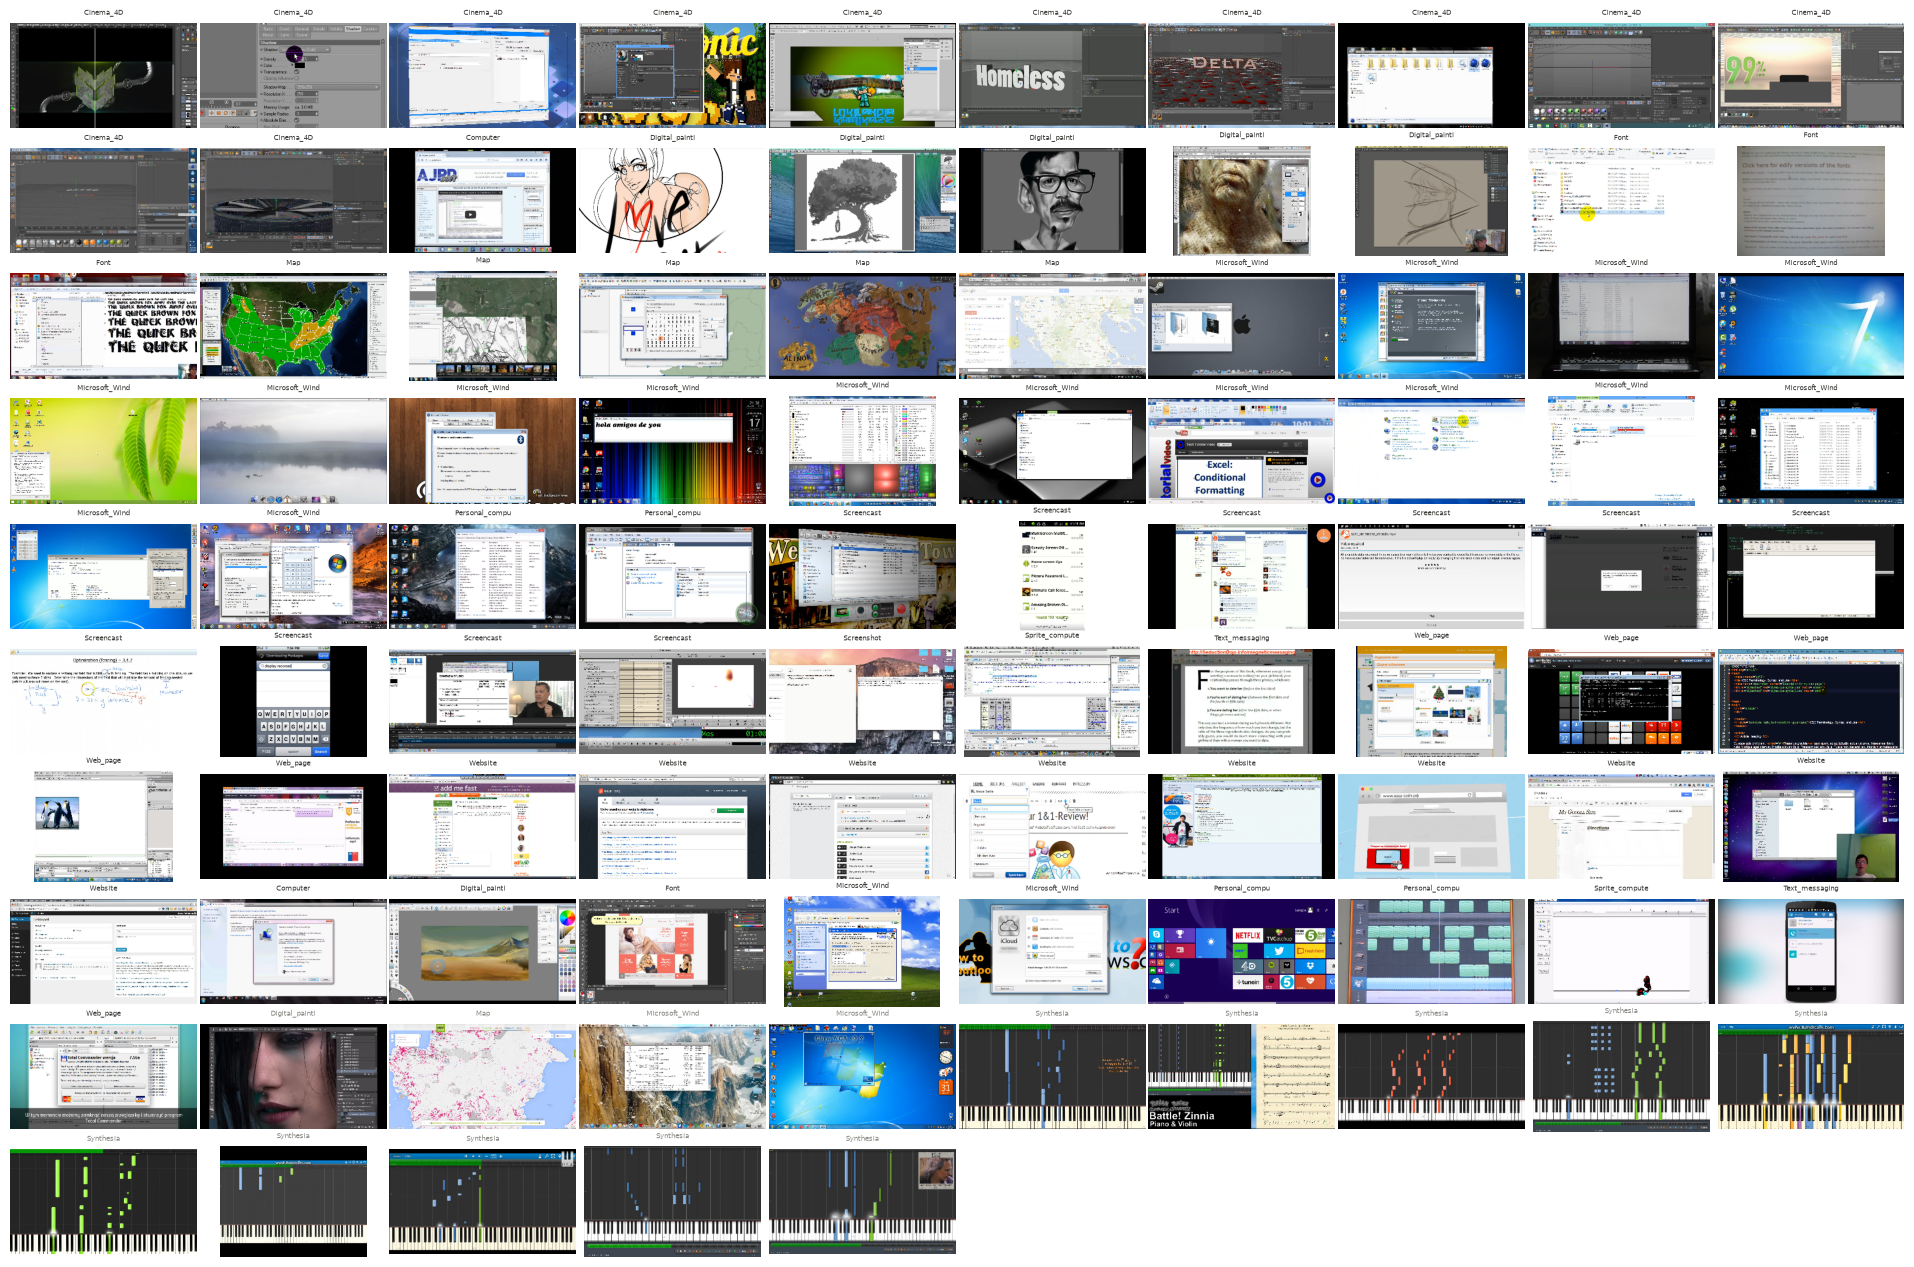

In [2]:
videos = [(group, video) for group, items in GROUPS.items() for video in items]
columns = 10
rows = -(-len(videos) // columns)
fig, axes = plt.subplots(rows, columns, figsize=(columns * 1.9, rows * 1.25))
for ax in axes.flat:
    ax.axis("off")
for ax, (group, video) in zip(axes.flat, videos):
    files = sorted(f["file"] for f in manifest["splits"][group]["sources"] if f["video"] == video)
    file = files[min(2, len(files) - 1)]
    frames, _ = sources.load_sequence(sources.RAW / "yt8m-videos" / file)
    ax.imshow(frames[len(frames) // 2][::4, ::4])
    ax.set_title(video.split("/")[0][:14], fontsize=5, color="#8a8a85" if group != "screens, 24-30 fps" else "#3d3d3a")
fig.tight_layout(pad=0.2)
plt.show()

## 2. Scores

Every client tile at every received frame of every clip (from N = 2: a clip is 32 frames), every
method on the same frames. Columns as in notebooks 9 and 10: the changed tiles (N+1 differs from
N), all tiles, the moving ones (the published search's gate open) capped at 50 dB with the gain
over the published search and its 95% range over **videos** (a video's clips are not
independent), and the moving tiles with the stop decided perfectly (the better of the method and
repeat per tile - a bound). Then the drawn validation set's moving tiles for the same methods, from
notebooks 9 and 10's caches.

In [3]:
CACHE.mkdir(parents=True, exist_ok=True)
found = {}
for group in GROUPS:
    path = CACHE / f"{SLUG[group]}.pkl"
    if path.exists():
        found[group] = pickle.loads(path.read_bytes())
        continue
    started = time.time()
    found[group] = recursive.load(manifest, group, FIELDS, PICTURES, published, pyramid, STILL, start=1)
    path.write_bytes(pickle.dumps(found[group]))
    print(f"{group}: {len(found[group]['tiles']['source'])} tiles in {time.time() - started:.0f}s")

ORDER = ["repeat", "mock: linear", "published search", "pyramid, whole-pixel (notebook 8)", "3DRS (notebook 9)",
         "masked network (notebook 10)"]
BASE = "published search"
rng = np.random.default_rng(SEED)


def over_videos(gain, mask, video_of, draws=2000):
    per = [gain[mask & (video_of == v)] for v in np.unique(video_of[mask])]
    means = [np.concatenate([per[i] for i in rng.integers(0, len(per), len(per))]).mean() for _ in range(draws)]
    return np.percentile(means, [2.5, 97.5])


def table(result, video_of):
    tiles = result["tiles"]
    moving, changed = tiles["moving"], tiles["changed"]
    capped = {name: np.minimum(result["wpsnr"][name], CAP) for name in ORDER}
    print(f"{len(moving)} tiles: {moving.mean():.0%} moving, {changed.mean():.0%} changed")
    print(f"{'wPSNR (dB)':<36}{'changed':>16}{'all':>16}{'moving, ≤ 50 dB':>18}{'95% over videos':>18}{'perfect stop':>14}")
    for name in ORDER:
        s, base = result["wpsnr"][name], result["wpsnr"][BASE]
        gain = capped[name] - capped[BASE]
        low, high = over_videos(gain, moving, video_of) if name != BASE else (0, 0)
        stop = np.maximum(capped[name], capped["repeat"])[moving].mean()
        print(f"{name:<36}{s[changed].mean():8.2f} ({s[changed].mean() - base[changed].mean():+5.2f})"
              f"{s.mean():8.2f} ({s.mean() - base.mean():+5.2f})"
              f"{capped[name][moving].mean():10.2f} ({gain[moving].mean():+5.2f})  [{low:+.2f}, {high:+.2f}]{stop:14.2f}")


for group, result in found.items():
    video_of = np.array([manifest["splits"][group]["sources"][s]["video"] for s in result["tiles"]["source"]])
    print(f"\n{'=' * 40}\n{group}\n{'=' * 40}")
    table(result, video_of)

drawn = pickle.loads((training.CHECKPOINT_DIR / "masked" / "val.pkl").read_bytes())
drawn3 = pickle.loads((training.CHECKPOINT_DIR / "recursive" / "val.pkl").read_bytes())
moving = drawn["tiles"]["moving"]
print(f"\n{'=' * 40}\nthe drawn validation set (notebooks 9 and 10), 60 fps\n{'=' * 40}")
print(f"{len(moving)} tiles: {moving.mean():.0%} moving, {drawn['tiles']['changed'].mean():.0%} changed")
names = {"repeat": (drawn, "repeat"), "published search": (drawn, "published search"),
         "pyramid, whole-pixel (notebook 8)": (drawn, "pyramid, whole-pixel (notebook 8)"),
         "3DRS (notebook 9)": (drawn3, "3DRS"), "masked network (notebook 10)": (drawn, "masked, gated")}
for name, (result, key) in names.items():
    m, c = result["tiles"]["moving"], result["tiles"]["changed"]
    print(f"{name:<36}{result['wpsnr'][key][c].mean():8.2f} changed{np.minimum(result['wpsnr'][key], CAP)[m].mean():10.2f} moving")


screens, 24-30 fps
32475 tiles: 51% moving, 18% changed
wPSNR (dB)                                   changed             all   moving, ≤ 50 dB   95% over videos  perfect stop
repeat                                 33.05 (+0.13)   63.05 (+0.42)     43.97 (+0.52)  [+0.29, +0.79]         43.97
mock: linear                           28.93 (-3.99)   54.69 (-7.95)     39.08 (-4.38)  [-4.68, -4.10]         44.01
published search                       32.93 (+0.00)   62.64 (+0.00)     43.45 (+0.00)  [+0.00, +0.00]         44.09
pyramid, whole-pixel (notebook 8)      32.83 (-0.10)   62.57 (-0.07)     43.29 (-0.16)  [-0.23, -0.10]         44.10
3DRS (notebook 9)                      32.79 (-0.14)   61.86 (-0.78)     42.55 (-0.90)  [-1.16, -0.66]         44.23
masked network (notebook 10)           33.04 (+0.11)   62.40 (-0.24)     43.49 (+0.04)  [+0.01, +0.08]         44.12

screens, 50-60 fps (seen in training)
1200 tiles: 49% moving, 11% changed
wPSNR (dB)                                   ch

## 3. What is different

How the recordings differ from the drawn scenes, on what the tile search assumes. Per set: the
share of tiles where something moved, and where N+1 differs from N; how far N+1 is from N on the
changed tiles (repeat's score) and what the search gains there; and - on a sample of moving tiles,
4 per clip, against notebook 10's moving validation tiles - how much of the change one motion per
tile leaves unexplained (notebook 10's `u`, per 16 px cell): the share of pixels where it explains
less than 40% of the change, and the share of the search's error that sits there.

In [4]:
untrained = models.Masked(models.TileSearch(4, 2, SHARPNESS, 2, FRACTION, still=STILL)).to(DEVICE).eval()


@torch.no_grad()
def unexplained(frames, meta):
    """(share of kept pixels with u > 0.6, share of the search's weighted squared error there, mean u)."""
    pixels = hard = error_all = error_hard = total_u = 0.0
    for first in range(0, len(frames), 32):
        previous, current, target = training.to_tensor(frames[first:first + 32]).unbind(1)
        parts = untrained.parts(previous, current)
        error = budget.squared(parts["search"][:, None], target)[:, 0]
        for i, box in enumerate(meta["box"][first:first + 32]):
            y, x, h, w = box
            u, e = parts["u"][i, 0, y:y + h, x:x + w], error[i, y:y + h, x:x + w]
            pixels += u.numel()
            hard += (u > 0.6).sum().item()
            total_u += u.sum().item()
            error_all += e.sum().item()
            error_hard += e[u > 0.6].sum().item()
    return hard / pixels, error_hard / max(error_all, 1e-9), total_u / pixels


samples = {}
for group in GROUPS:
    path = CACHE / f"tiles_{SLUG[group]}"
    samples[group] = masked.load(None, path) or masked.build(manifest, group, published, 4, seed=SEED, path=path)
samples["drawn validation (60 fps)"] = masked.load("val")

print(f"{'':<42}{'moving':>8}{'changed':>9}{'repeat, changed':>17}{'search gain':>13}"
      f"{'u > 0.6: pixels':>17}{'its error':>11}{'mean u':>8}")
for group in [*GROUPS, "drawn validation (60 fps)"]:
    result = found.get(group, drawn)
    tiles, w = result["tiles"], result["wpsnr"]
    c = tiles["changed"]
    share, error_share, mean_u = unexplained(*samples[group])
    print(f"{group:<42}{tiles['moving'].mean():8.0%}{c.mean():9.0%}{w['repeat'][c].mean():14.2f} dB"
          f"{w[BASE][c].mean() - w['repeat'][c].mean():+10.2f} dB{share:16.0%}{error_share:11.0%}{mean_u:8.2f}")

                                            moving  changed  repeat, changed  search gain  u > 0.6: pixels  its error  mean u
screens, 24-30 fps                             51%      18%         33.05 dB     -0.13 dB             18%        70%    0.29
screens, 50-60 fps (seen in training)          49%      11%         36.25 dB     -0.01 dB             11%        85%    0.24
Synthesia                                      91%      68%         31.75 dB     +2.37 dB             16%        87%    0.24
drawn validation (60 fps)                      55%      40%         26.30 dB     +5.41 dB             18%        59%    0.28


## 4. Examples

From the 24-30 fps screens' sampled moving tiles: the changed ones at the 25th, 50th and 75th
percentile of the tile search's score - typical tiles, not chosen ones. Rows: the received frames
and N+1; what repeat, the tile search and the masked network make; their errors (black right,
yellow 48 luma levels or more wrong).

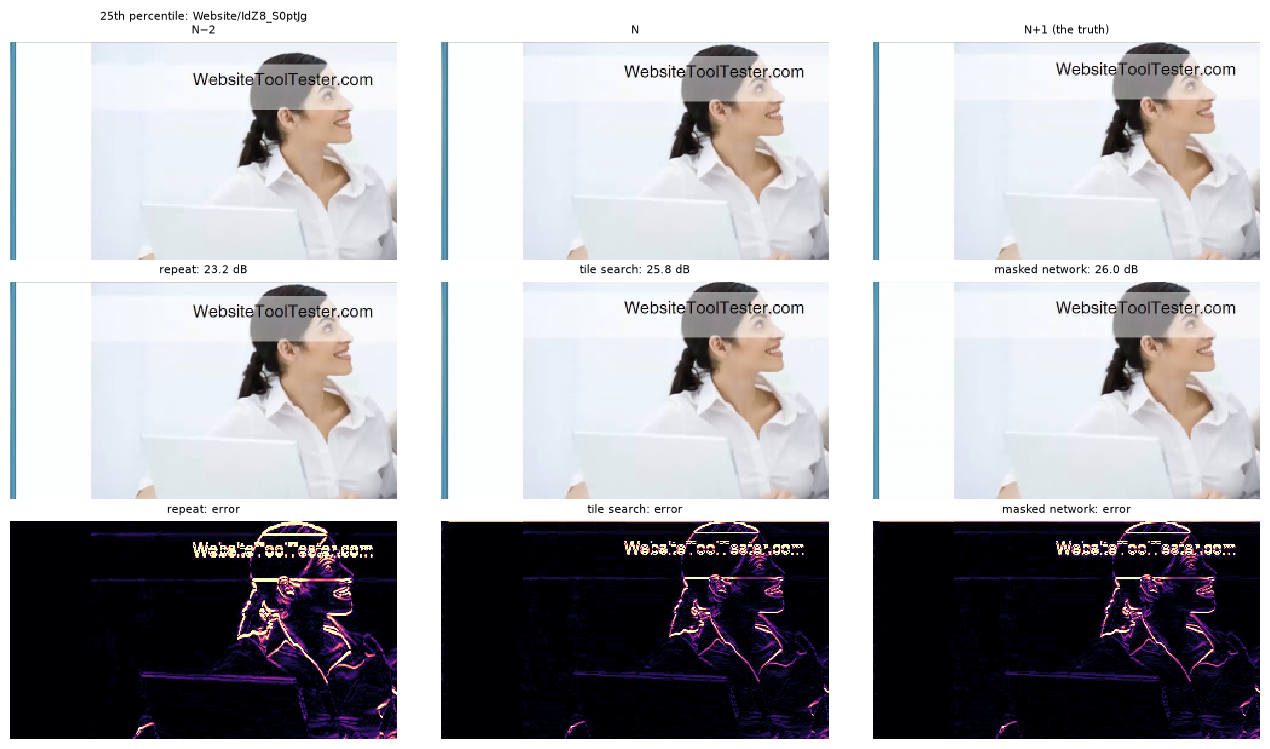

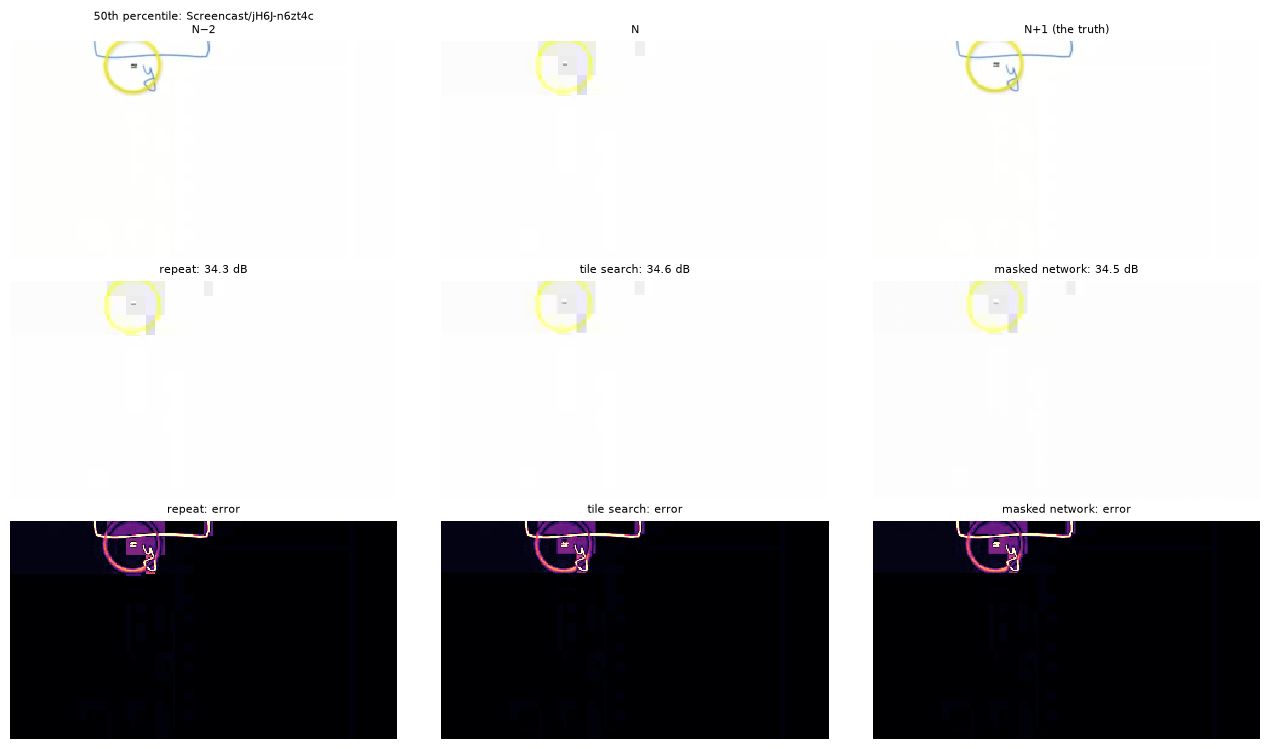

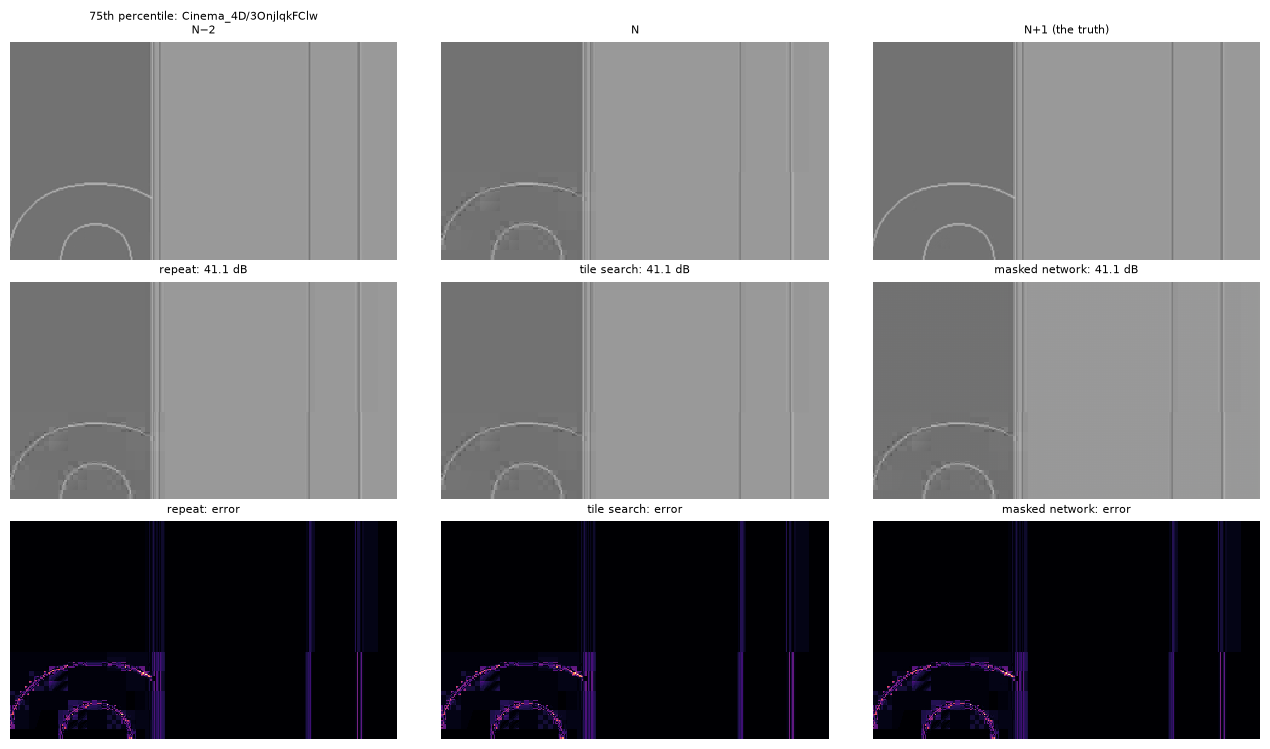

In [5]:
frames, meta = samples["screens, 24-30 fps"]
changed = np.array([runs.changed_share(clips.kept(f[1], tuple(b), True), clips.kept(f[2], tuple(b), True)) >= runs.MOVING_SHARE
                    for f, b in zip(frames, meta["box"])])
search_model = models.Motion(search=published, learned=False).to(DEVICE).eval()
scores = masked.scores(search_model, frames, meta)
pool = np.flatnonzero(changed)
picks = {f"{q}th percentile": pool[np.argmin(np.abs(scores[pool] - np.percentile(scores[pool], q)))] for q in (25, 50, 75)}
for title, i in picks.items():
    previous, current, target = training.to_tensor(frames[i:i + 1]).unbind(1)
    box = tuple(meta["box"][i])
    with torch.no_grad():
        made = {"repeat": current, "tile search": search_model(previous, current), "masked network": network(previous, current).clamp(0, 1)}
    y, x, h, w = box
    crop = lambda image: image[..., y:y + h, x:x + w]
    fig, axes = plt.subplots(3, 3, figsize=(13, 7.4))
    source = manifest["splits"]["screens, 24-30 fps"]["sources"][meta["source"][i]]
    for ax, image, label in zip(axes[0], (previous, current, target), ("N−2", "N", "N+1 (the truth)")):
        show.picture(ax, crop(image), f"{label}" if label != "N−2" else f"{title}: {source['video']}\nN−2")
    for ax, (name, image) in zip(axes[1], made.items()):
        score = history.sample_wpsnr(crop(image), crop(target)).item()
        show.picture(ax, crop(image), f"{name}: {score:.1f} dB")
        show.error(axes[2][list(made).index(name)], crop(image), crop(target), f"{name}: error")
    fig.tight_layout(pad=0.4)
    plt.show()

## 5. Duplicated frames

Screen recorders often capture slower than the video's rate and repeat frames to fill it: a
30 fps upload of a 15 fps capture shows every frame twice. Then N+1 is often a copy of N - repeat
is exact by construction - or already a copy of N+2. The raw source, before the stream, says
which: per clip, the mean |luma change| between consecutive frames, and a step under 0.25 levels
counts as no change. Each tile at received frame N falls in one of four classes - N+1 a new frame
(N → N+1 and N+1 → N+2 both change), a copy of N, a copy of N+2, or no change from N to N+2 at
all - and the fair test of extrapolation is the first.

In [6]:
import json

path = CACHE / "raw_steps.json"
if path.exists():
    steps = json.loads(path.read_text())
else:
    steps = {}
    for split in manifest["splits"].values():
        for source in split["sources"]:
            frames, _ = sources.load_sequence(sources.RAW / source["dataset"] / source["file"])
            luma = frames.astype(np.float32) @ np.array([0.299, 0.587, 0.114], np.float32)
            steps[source["file"]] = np.abs(np.diff(luma, axis=0)).mean(axis=(1, 2)).tolist()
    path.write_text(json.dumps(steps))

STEP = 0.25
CLASSES = ("N+1 a new frame", "N+1 a copy of N", "N+1 a copy of N+2", "no change from N to N+2")


def classes(group):
    tiles = found[group]["tiles"]
    split = manifest["splits"][group]["sources"]
    out = []
    for s, n in zip(tiles["source"], tiles["frame"]):
        d = steps[split[s]["file"]]
        if n + 1 >= len(d):
            out.append("unknown")
            continue
        a, b = d[n] > STEP, d[n + 1] > STEP
        out.append(CLASSES[0] if a and b else CLASSES[1] if b else CLASSES[2] if a else CLASSES[3])
    return np.array(out)


for group in GROUPS:
    split = manifest["splits"][group]["sources"]
    kinds = {"no motion": 0, "frames repeated": 0, "every frame new": 0}
    for source in split:
        d = np.array(steps[source["file"]]) > STEP
        if d.sum() < 3:
            kinds["no motion"] += 1
            continue
        repeated = (~d[1:-1]) & (d[:-2] | d[2:])
        kinds["frames repeated" if repeated.sum() >= 0.3 * d.sum() else "every frame new"] += 1
    print(f"{group}: {len(split)} clips - " + ", ".join(f"{v} {k}" for k, v in kinds.items()))

for group in GROUPS:
    result, found_classes = found[group], classes(group)
    tiles = result["tiles"]
    video_of = np.array([manifest["splits"][group]["sources"][s]["video"] for s in tiles["source"]])
    print(f"\n{'=' * 40}\n{group}\n{'=' * 40}")
    print(f"{'changed tiles, wPSNR (dB)':<36}" + "".join(f"{c:>22}" for c in CLASSES))
    print(f"{'tiles (changed)':<36}" + "".join(f"{(tiles['changed'] & (found_classes == c)).sum():22}" for c in CLASSES))
    for name in ORDER:
        print(f"{name:<36}" + "".join(f"{result['wpsnr'][name][tiles['changed'] & (found_classes == c)].mean():22.2f}"
                                      for c in CLASSES))
    fresh = tiles["changed"] & (found_classes == CLASSES[0])
    if fresh.sum() > 50:
        print(f"\nN+1 a new frame, changed tiles: gain over repeat, 95% over videos ({len(set(video_of[fresh]))} videos)")
        for name in ORDER[1:]:
            gain = result["wpsnr"][name] - result["wpsnr"]["repeat"]
            low, high = over_videos(gain, fresh, video_of)
            print(f"  {name:<36}{gain[fresh].mean():+6.2f} dB  [{low:+.2f}, {high:+.2f}]")

screens, 24-30 fps: 405 clips - 232 no motion, 129 frames repeated, 44 every frame new
screens, 50-60 fps (seen in training): 20 clips - 15 no motion, 5 frames repeated, 0 every frame new
Synthesia: 50 clips - 1 no motion, 6 frames repeated, 43 every frame new

screens, 24-30 fps
changed tiles, wPSNR (dB)                  N+1 a new frame       N+1 a copy of N     N+1 a copy of N+2no change from N to N+2
tiles (changed)                                       2352                   136                   897                  1409
repeat                                               29.98                 39.83                 27.56                 39.86
mock: linear                                         26.73                 33.17                 25.19                 34.78
published search                                     30.35                 36.84                 27.26                 39.18
pyramid, whole-pixel (notebook 8)                    30.29                 36.00             

## What it says

- **On real screens the tile search is about as good as repeating the frame.** On the 81 screen
  videos at 24-30 fps, none seen in training: 32.93 dB on the changed tiles against repeat's
  33.05, and 43.45 on the moving tiles against 43.97 (95% over videos, repeat ahead by +0.29 to
  +0.79). On the drawn validation set the search was +5.41 dB over repeat on the changed tiles.
- **Part of that is how screen videos are made.** 232 of the 405 clips do not move at all; of
  the 173 that do, 129 repeat frames - a slower capture filled up to the video's rate - and only
  44 have a new frame every time. Where N+1 is a copy of N, repeat is exact; where it is already
  a copy of N+2, half the motion is half wrong.
- **Where N+1 is a new frame, motion is worth a few tenths of a dB.** On those changed tiles
  (2,352, from 51 videos), against repeat: the published search **+0.37 dB** (95% over videos
  −0.02 to +0.77), the pyramid +0.31, 3DRS +0.74 (+0.13 to +1.38), the masked network +0.61
  (+0.22 to +1.03), the mock −3.25. A fifteenth of the drawn set's gain. Real screens change in
  ways one translation does not follow: an annotation that comes and goes, a highlight, a fade,
  a zoom, a still watermark over a moving picture ("Examples" shows the last two).
- **The order of the motion methods changes.** On real screens the methods that move part of a
  tile - 3DRS, the masked network - lead the tile search; on the drawn set both lost or tied.
  The cells where one motion per tile explains less than 40% of the change hold 70% of the
  search's error on real screens, against 59% on the drawn set. At gains this small the order is
  not settled.
- **Synthesia shows what rigid motion is worth.** Bars falling at a constant speed over a still
  keyboard - the drawn scenes' kind of motion: where N+1 is new, the search is +2.55 dB over
  repeat and 3DRS +5.56, since only a motion per block can move the bars without the keyboard.
- **The 60 fps screen captures say nothing**: 15 of their 20 clips do not move, and 11 changed
  tiles have a new N+1.

These are YouTube tutorials, not a live session: edited (zooms, annotations), recompressed by
YouTube before the stream's own codec, and at 24-30 fps, so the client receives 12-15 fps and the
motion between received frames is twice the 60 fps case. They are nearer to a real screen than
the drawn scenes, not the same as one. But the drawn set's headline - +11 dB on samples, +5.4 on
whole tiles - is mostly its own: whole-window rigid scrolls and pans, every change on a received
frame. On real screen content, extrapolating by motion gains a few tenths of a dB over repeating
the last frame. What would settle it is a real 60 fps recording of a desktop in use, and a live
session.